In [ ]:
import os
from huggingface_hub import login



HF_TOKEN = ""
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [2]:
import os
from huggingface_hub import login
# Do NOT hard-code the token. Add it as a Kaggle secret named HF_TOKEN (Add-ons -> Secrets) or export HF_TOKEN.
_tok = os.environ.get("HF_TOKEN", "").strip()
if not _tok:
    try:
        from kaggle_secrets import UserSecretsClient
        _tok = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        _tok = ""
if _tok:
    os.environ["HF_TOKEN"] = _tok; login(token=_tok); print("Hugging Face login successful.")
else:
    print("No HF_TOKEN found - the dataset download may fail if the repo is gated.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


In [3]:
#imports + master switches + hyper-parameters
import os, sys, json, gc, time, math, random, re, shutil, pickle, hashlib, subprocess
import importlib.util, warnings, functools, heapq
from pathlib import Path
from dataclasses import dataclass, fields, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint
from tqdm.auto import tqdm
from IPython.display import display

warnings.filterwarnings("ignore")

# ===================================================================
# MASTER SWITCHES
# ===================================================================
SMOKE_TEST          = False   # True -> synthetic data + tiny random model, no downloads (dry-run of the whole pipeline in minutes)
RUN_SELF_TESTS      = True
RUN_BENCHMARK       = True    # quick micro-batch benchmark at ctx 2048 only (~1-2 min, protects against OOM)
RUN_STAGE_C         = True    # the ONLY training run: 5 epochs on 100% of train

PREV_STATE_DIR = ""           # path of a previous run's folder to resume from (e.g. a saved Kaggle dataset)

# ===================================================================
# DATA / SPLITS  (same protocol as the enc-dec notebook)
# ===================================================================
VAL_B_SIZE   = 400
ABL_TRAIN_N  = 1200           # "subset of train" for ablations
ABL_VAL_N    = 120
ABL_EPOCHS   = 2

# ===================================================================
# DEFAULT EXPERIMENT (every ablation overrides a few of these keys)
# ===================================================================
SEP_TEXT   = "\n\nSUMMARY:\n"
BASE_EXP = dict(
    ctx=2048,              # winner of the SWA+Houlsby study
    sumtok=512,            # summary tokens used as training target AND generation cap
    strategy="extract",    # importance-based sentence extraction
    rope_mode="extrap",
    prep="clean",
    train_norms=True,      # RMSNorm scales trained (as in the best adapter config 'A_train_norms')
    lr=5e-4,               # LoRA lr (adapters used 1e-3; LoRA is usually run ~2x lower). Single knob - change if you like.
)

# LoRA (Assignment-4 style).  targets: subset of q,k,v,o  -> q_proj, k_proj, v_proj, out_proj of EVERY block
LORA_CFG = dict(rank=16, alpha=32, targets=("q", "k", "v", "o"), swap_ab=False)

# Final recipe taken from the Houlsby run (not re-tuned)
FINAL_EPOCHS = 5
FINAL_DECODE = {"num_beams": 1, "no_repeat_ngram": 4, "repetition_penalty": 1.2, "min_new_tokens": 16, "max_new_tokens": 512}
FINAL_DEDUPE, FINAL_TRIM = True, True

# ===================================================================
# OPTIMISATION
# ===================================================================
EFFECTIVE_BS_ABL = 8
EFFECTIVE_BS     = 16
WEIGHT_DECAY     = 0.01
WARMUP_FRAC      = 0.05
MAX_GRAD_NORM    = 1.0

# selection guard: BERTScore-F1 rewards very short outputs when the references are ~850 words (see report cell).
# Candidates whose mean prediction is shorter than this are not eligible for "best". 0 disables the guard.
MIN_PRED_WORDS = 100

MEM_CAP_GB  = 13.0
NUM_WORKERS = 0
GEN_BS      = 16

USE_AMP   = torch.cuda.is_available()
AMP_DTYPE = torch.float16
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_everything(SEED)

# ===================================================================
# DIRECTORIES
# ===================================================================
ON_KAGGLE = Path("/kaggle").exists()
WORK = Path("/kaggle/working/phase6_swa_lora") if ON_KAGGLE else Path("./phase6_swa_lora" + ("_smoke" if SMOKE_TEST else ""))
DATA_DIR, CACHE_DIR = WORK/"raw_data", WORK/"data_cache"
CKPT_DIR, OUT_DIR, SUBMISSION_DIR = WORK/"checkpoints", WORK/"outputs", WORK/"submission"
for p in [WORK, DATA_DIR, CACHE_DIR, CKPT_DIR, OUT_DIR, SUBMISSION_DIR]:
    p.mkdir(parents=True, exist_ok=True)

if PREV_STATE_DIR and Path(PREV_STATE_DIR).exists() and not (OUT_DIR/"state.json").exists():
    shutil.copytree(PREV_STATE_DIR, WORK, dirs_exist_ok=True)
    print("Restored previous run from", PREV_STATE_DIR)

STATE_PATH = OUT_DIR/"state.json"
def _json_default(o):
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (set, tuple)):   return list(o)
    return str(o)
def load_state(): return json.load(open(STATE_PATH)) if STATE_PATH.exists() else {}
def save_state(): json.dump(STATE, open(STATE_PATH, "w"), indent=2, default=_json_default)
STATE = load_state()
STATE.setdefault("ablation", {}); STATE.setdefault("exps", {}); STATE.setdefault("bench", {})

print("="*65); print("PHASE 6 | SWA decoder + LoRA (from scratch)"); print("="*65)
print("Kaggle:", ON_KAGGLE, "| smoke:", SMOKE_TEST, "| torch", torch.__version__, "| device", DEVICE)
if torch.cuda.is_available():
    g = torch.cuda.get_device_properties(0)
    print(f"GPU: {g.name} | {g.total_memory/1024**3:.1f} GB | CUDA {torch.version.cuda}")
print("Work dir:", WORK.resolve()); print("State keys already completed:", list(STATE.keys()))

PHASE 6 | SWA decoder + LoRA (from scratch)
Kaggle: True | smoke: False | torch 2.11.0+cu130 | device cuda
GPU: Tesla T4 | 14.6 GB | CUDA 13.0
Work dir: /kaggle/working/phase6_swa_lora
State keys already completed: ['ablation', 'exps', 'bench']


### Data
Hugging Face token: **do not paste it in a notebook.** Add it as a Kaggle secret named `HF_TOKEN` (Add-ons → Secrets). The token that is hard-coded in your Phase-1 / Phase-6 notebooks is public in those files — revoke it in your HF settings and create a new one.

In [4]:
#download phase 6 data (same repo/files as the enc-dec notebook) + clean exactly the same way
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_FILES = {"train": "Phase_6_Summ/Train/train.json", "test": "Phase_6_Summ/Test/test.json"}
LOCAL_DATA_DIR = ""     # folder holding train.json / test.json to skip the download

def get_hf_token():
    token = os.environ.get("HF_TOKEN", "").strip()
    if not token and ON_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            token = ""
    return token or None

def make_smoke_records(n_train=160, n_test=12, seed=0):
    rng = np.random.RandomState(seed)
    words = ["court", "appeal", "section", "act", "petitioner", "respondent", "held", "order", "tribunal", "contract",
             "tax", "evidence", "judgment", "bench", "statute", "writ", "accused", "bail", "decree", "plaintiff"]
    def para(n): return " ".join(rng.choice(words, n)) + "."
    def doc(): return "\n".join(para(rng.randint(8, 25)) for _ in range(rng.randint(40, 160)))
    def summ(): return " ".join(para(rng.randint(8, 20)) for _ in range(rng.randint(12, 40)))
    tr = [{"id": str(i), "document": doc(), "summary": summ()} for i in range(n_train)]
    te = [{"id": f"t{i}", "document": doc()} for i in range(n_test)]
    return tr, te

if SMOKE_TEST:
    train_records, test_records = make_smoke_records()
else:
    if importlib.util.find_spec("huggingface_hub") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
    from huggingface_hub import hf_hub_download
    dataset_paths = {}
    if LOCAL_DATA_DIR:
        for split in ["train", "test"]:
            dataset_paths[split] = Path(LOCAL_DATA_DIR)/f"{split}.json"; assert dataset_paths[split].is_file(), dataset_paths[split]
    else:
        tok_ = get_hf_token()
        for split, fn in HF_FILES.items():
            dataset_paths[split] = Path(hf_hub_download(repo_id=HF_DATASET_REPO, filename=fn, repo_type="dataset",
                                                        token=tok_, local_dir=str(DATA_DIR/"hf_download")))
    for k, v in dataset_paths.items(): print(f"{k}: {v}  ({v.stat().st_size/1024**2:.1f} MB)")
    with open(dataset_paths["train"], encoding="utf-8") as f: train_records = json.load(f)
    with open(dataset_paths["test"],  encoding="utf-8") as f: test_records  = json.load(f)

#drop empty text + exact-duplicate documents (identical logic to the enc-dec notebook -> 7001 clean records)
clean_train_records, seen = [], set()
n_empty = n_dup = 0
for r in train_records:
    d, s = r.get("document"), r.get("summary")
    if not isinstance(d, str) or not d.strip() or not isinstance(s, str) or not s.strip():
        n_empty += 1; continue
    h = hashlib.sha256(d.encode("utf-8")).hexdigest()
    if h in seen: n_dup += 1; continue
    seen.add(h)
    clean_train_records.append({"id": str(r["id"]), "document": d, "summary": s})
print(f"train raw={len(train_records)} | removed empty={n_empty} dup={n_dup} | clean={len(clean_train_records)} | test={len(test_records)}")
if not SMOKE_TEST and len(clean_train_records) != 7001:
    print("WARNING: expected 7001 clean training records (as in the enc-dec notebook), got", len(clean_train_records))
assert len({r["id"] for r in clean_train_records}) == len(clean_train_records)

Phase_6_Summ/Train/train.json: reconstructing file:   0%|          |  0.00B /  211MB            

Phase_6_Summ/Train/train.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/2.73M [00:00<?, ?B/s]

train: /kaggle/working/phase6_swa_lora/raw_data/hf_download/Phase_6_Summ/Train/train.json  (200.8 MB)
test: /kaggle/working/phase6_swa_lora/raw_data/hf_download/Phase_6_Summ/Test/test.json  (2.6 MB)
train raw=7030 | removed empty=2 dup=27 | clean=7001 | test=100


### Phase-1 tokenizer (A-1 byte-level BPE, same loader as the Phase-1 / enc-dec notebooks; word cache for speed; byte-safe decoder)

In [5]:
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]
N_SPECIAL, N_BYTES = 4, 256
BASE_VOCAB_SIZE = N_SPECIAL + N_BYTES
WORD_RE = re.compile(r"\S+")

class A1BPETokenizer:
    def __init__(self, itos, id_to_bytes, merges):
        self.itos = list(itos)
        self._id_to_bytes = list(id_to_bytes)
        self.merges = [tuple(m) for m in merges]
        self.vocab_size = len(self.itos)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self._byte_to_id = {bytes([b]): N_SPECIAL + b for b in range(256)}
        self._merge_ranks = {pair: rank for rank, pair in enumerate(self.merges)}
        self._word_cache = functools.lru_cache(maxsize=300000)(lambda w: tuple(self._encode_word(w)))

    def _encode_word(self, word):
        raw = word.encode("utf-8")
        seq = [self._byte_to_id[bytes([b])] for b in raw]
        if len(seq) < 2 or not self._merge_ranks:
            return seq
        n = len(seq)
        prev = [-1] + list(range(n - 1))
        nxt = list(range(1, n)) + [-1]
        active = [True] * n
        heap = []
        for i in range(n - 1):
            rank = self._merge_ranks.get((seq[i], seq[i + 1]))
            if rank is not None:
                heapq.heappush(heap, (rank, i, i + 1))
        while heap:
            rank, left, right = heapq.heappop(heap)
            if not active[left] or not active[right]: continue
            if nxt[left] != right or prev[right] != left: continue
            if self._merge_ranks.get((seq[left], seq[right])) != rank: continue
            seq[left] = BASE_VOCAB_SIZE + rank
            active[right] = False
            right_next = nxt[right]
            nxt[left] = right_next
            if right_next != -1: prev[right_next] = left
            left_prev = prev[left]
            if left_prev != -1:
                nr = self._merge_ranks.get((seq[left_prev], seq[left]))
                if nr is not None: heapq.heappush(heap, (nr, left_prev, left))
            if right_next != -1:
                nr = self._merge_ranks.get((seq[left], seq[right_next]))
                if nr is not None: heapq.heappush(heap, (nr, left, right_next))
        out, i = [], 0
        while i != -1:
            if active[i]: out.append(seq[i])
            i = nxt[i]
        return out

    def encode(self, text):
        ids, cursor = [], 0
        for m in WORD_RE.finditer(text):
            if m.start() > cursor:
                ids.extend(N_SPECIAL + b for b in text[cursor:m.start()].encode("utf-8"))
            ids.extend(self._word_cache(m.group(0)))
            cursor = m.end()
        if cursor < len(text):
            ids.extend(N_SPECIAL + b for b in text[cursor:].encode("utf-8"))
        return ids

    def decode(self, ids):
        chunks, buf = [], bytearray()
        def flush():
            if buf:
                chunks.append(bytes(buf).decode("utf-8", errors="strict")); buf.clear()
        for idx in ids:
            idx = int(idx)
            if idx < N_SPECIAL: flush(); chunks.append(SPECIAL_TOKENS[idx])
            else: buf.extend(self._id_to_bytes[idx])
        flush()
        return "".join(chunks)

def load_a1_tokenizer(path):
    with open(path, encoding="utf-8") as f: payload = json.load(f)
    itos, merges = payload["itos"], [tuple(p) for p in payload["merges"]]
    id_to_bytes = [b""] * N_SPECIAL + [bytes([b]) for b in range(N_BYTES)]
    for l, r in merges:
        id_to_bytes.append(id_to_bytes[l] + id_to_bytes[r])
    assert len(itos) == len(id_to_bytes)
    t = A1BPETokenizer(itos, id_to_bytes, merges)
    assert t.vocab_size == 50000 and t.itos[:4] == SPECIAL_TOKENS
    return t

def find_artifact(name, preferred):
    if preferred and Path(preferred).is_file(): return Path(preferred)
    for root in [Path("/kaggle/input"), Path("/kaggle/working"), Path(".")]:
        if root.exists():
            for r, _, files in os.walk(root):
                if name in files: return Path(r)/name
    raise FileNotFoundError(f"{name} not found - add the Phase-1 dataset to the notebook inputs (or set the path above)")

def make_smoke_tokenizer(n_merges=600):
    #tiny BPE trained on the synthetic corpus so that the smoke test needs no files
    wf = {}
    for r in train_records[:60]:
        for w in WORD_RE.findall(r["document"]): wf[w] = wf.get(w, 0) + 1
    words = [[N_SPECIAL + b for b in w.encode()] for w in wf]; freqs = list(wf.values())
    id_to_bytes = [b""] * N_SPECIAL + [bytes([b]) for b in range(256)]
    itos = list(SPECIAL_TOKENS) + [f"<0x{b:02X}>" for b in range(256)]; merges = []
    for _ in range(n_merges):
        cnt = {}
        for w, f in zip(words, freqs):
            for p in zip(w, w[1:]): cnt[p] = cnt.get(p, 0) + f
        if not cnt: break
        best = max(cnt, key=cnt.get); new_id = len(itos); merges.append(best)
        id_to_bytes.append(id_to_bytes[best[0]] + id_to_bytes[best[1]]); itos.append(f"<m{new_id}>")
        for k, w in enumerate(words):
            i, out = 0, []
            while i < len(w):
                if i < len(w) - 1 and (w[i], w[i + 1]) == best: out.append(new_id); i += 2
                else: out.append(w[i]); i += 1
            words[k] = out
    return A1BPETokenizer(itos, id_to_bytes, merges)

if SMOKE_TEST:
    tokenizer = make_smoke_tokenizer()
else:
    TOKENIZER_PATH = find_artifact("legal_bpe_a1_50k_final.json", "/kaggle/input/datasets/vishwasp23/tokensss/legal_bpe_a1_50k_final.json")
    tokenizer = load_a1_tokenizer(TOKENIZER_PATH)
    print("tokenizer:", TOKENIZER_PATH)
VOCAB = tokenizer.vocab_size
PAD_ID, UNK_ID, BOS_ID, EOS_ID = [tokenizer.stoi[t] for t in SPECIAL_TOKENS]
print("vocab", VOCAB, "| PAD/UNK/BOS/EOS =", PAD_ID, UNK_ID, BOS_ID, EOS_ID)

def safe_decode(ids):
    #generation can stop inside a multi-byte character -> never raise
    buf = bytearray()
    for i in ids:
        i = int(i)
        if i >= N_SPECIAL: buf.extend(tokenizer._id_to_bytes[i])
    return buf.decode("utf-8", errors="replace")

for t in ["The petitioner challenged the decision of the High Court.", "Section 13(5) of the Bihar Sales Tax Act, 1947."]:
    assert tokenizer.decode(tokenizer.encode(t)) == t and safe_decode(tokenizer.encode(t)) == t
SEP_IDS = tokenizer.encode(SEP_TEXT)
print("tokenizer round-trip OK | separator", repr(SEP_TEXT), "->", len(SEP_IDS), "tokens")

tokenizer: /kaggle/input/datasets/vishwaspathania/tokenssss/legal_bpe_a1_50k_final.json
vocab 50000 | PAD/UNK/BOS/EOS = 0 1 2 3
tokenizer round-trip OK | separator '\n\nSUMMARY:\n' -> 5 tokens


### Pre-processing + tokenisation (cached)
`clean` = the exact Phase-1 cleaning rules (NFKC, remove signature lines, collapse whitespace) so the text matches what the decoder saw during pre-training; `raw` = untouched text (ablation `P_raw`). Tokenisation is lazy and memoised per `(prep, id, field)`; the cache is pickled so later sessions do not re-tokenise.

In [6]:
import unicodedata

def clean_text(text):
    #Phase-1 cleaning rules (same as the Phase-1 notebook)
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("\r\n", "\n").replace("\r", "\n").replace("\x00", " ").replace("\ufffd", " ")
    text = re.sub(r"(?im)^\s*Signature Not Verified\s*$", "", text)
    text = re.sub(r"(?im)^\s*Digitally signed by.*$", "", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    text = re.sub(r"\n[ \t]+", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def prep_text(text, prep):
    return clean_text(text) if prep == "clean" else text

TOK_CACHE_PATH = CACHE_DIR/"tok_cache_v1.pkl"
TOK_CACHE = pickle.load(open(TOK_CACHE_PATH, "rb")) if (TOK_CACHE_PATH.exists() and not SMOKE_TEST) else {}
_cache_dirty = [0]

def get_tokens(rec, field, prep):
    key = (prep, rec["id"], field)
    v = TOK_CACHE.get(key)
    if v is None:
        v = np.asarray(tokenizer.encode(prep_text(rec[field], prep)), dtype=np.uint16)   #vocab 50k < 65536
        TOK_CACHE[key] = v; _cache_dirty[0] += 1
    return v

def flush_tok_cache():
    if _cache_dirty[0] and not SMOKE_TEST:
        with open(TOK_CACHE_PATH, "wb") as f: pickle.dump(TOK_CACHE, f)
        _cache_dirty[0] = 0

#splits (same seed/protocol as the enc-dec notebook)
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(clean_train_records))
if SMOKE_TEST: VAL_B_SIZE, ABL_TRAIN_N, ABL_VAL_N = 24, 48, 12
stageB_val   = [clean_train_records[i] for i in perm[:VAL_B_SIZE]]
stageB_train = [clean_train_records[i] for i in perm[VAL_B_SIZE:]]
abl_train = [clean_train_records[i] for i in perm[VAL_B_SIZE: VAL_B_SIZE + ABL_TRAIN_N]]
abl_val   = [clean_train_records[i] for i in perm[VAL_B_SIZE + ABL_TRAIN_N: VAL_B_SIZE + ABL_TRAIN_N + ABL_VAL_N]]
full_train = clean_train_records
print(f"stageB_train={len(stageB_train)} stageB_val={len(stageB_val)} | abl_train={len(abl_train)} abl_val={len(abl_val)} | full_train={len(full_train)} test={len(test_records)}")

#length statistics on a sample (the full 7001 are tokenised later when needed)
stat_sample = clean_train_records[:min(600, len(clean_train_records))]
doc_len = np.array([len(get_tokens(r, "document", "clean")) for r in tqdm(stat_sample, desc="stats: docs")])
sum_len = np.array([len(get_tokens(r, "summary", "clean")) for r in tqdm(stat_sample, desc="stats: summaries")])
print("\nDocument tokens (cleaned, sample):", {k: int(v) for k, v in zip(["mean","p50","p90","p99","max"], [doc_len.mean(), *np.percentile(doc_len,[50,90,99]), doc_len.max()])})
print("Summary tokens  (cleaned, sample):", {k: int(v) for k, v in zip(["mean","p50","p90","p99","max"], [sum_len.mean(), *np.percentile(sum_len,[50,90,99]), sum_len.max()])})
rows = []
for ctx, sumtok in [(1024, 256), (2048, 256), (2048, 512), (4096, 256), (4096, 512)]:
    B = ctx - 1 - len(SEP_IDS) - sumtok
    rows.append({"ctx": ctx, "sumtok": sumtok, "doc_budget": B, "docs_fully_covered_%": (doc_len <= B).mean()*100,
                 "mean_doc_retention_%": (np.minimum(doc_len, B)/doc_len).mean()*100,
                 "mean_target_retention_%": (np.minimum(sum_len, sumtok)/sum_len).mean()*100})
print("\nWhat a single decoder window can see (head truncation):"); display(pd.DataFrame(rows).round(1))
flush_tok_cache()

stageB_train=6601 stageB_val=400 | abl_train=1200 abl_val=120 | full_train=7001 test=100


stats: docs:   0%|          | 0/600 [00:00<?, ?it/s]

stats: summaries:   0%|          | 0/600 [00:00<?, ?it/s]


Document tokens (cleaned, sample): {'mean': 9220, 'p50': 6550, 'p90': 16056, 'p99': 63004, 'max': 186796}
Summary tokens  (cleaned, sample): {'mean': 1799, 'p50': 1311, 'p90': 3292, 'p99': 10274, 'max': 36746}

What a single decoder window can see (head truncation):


,ctx,sumtok,doc_budget,docs_fully_covered_%,mean_doc_retention_%,mean_target_retention_%
0,1024,256,762,0.5,14.7,23.6
1,2048,256,1786,3.2,33.3,23.6
2,2048,512,1530,2.0,28.9,44.9
3,4096,256,3834,20.3,61.3,23.6
4,4096,512,3578,18.5,58.5,44.9


### Phase-1 decoder (re-declared once, **same parameter names → `strict=True` load**)
Same maths as `LegalDecoderLM` in the Phase-1 notebook (GQA 12/4, RoPE, RMSNorm, SwiGLU, tied head, local window 128 on layers 1-3, 5-7, 9-11, 13-15; global on layers 4, 8, 12, 16). Changes that do **not** alter the function:

* attention runs through `F.scaled_dot_product_attention` (query-chunked for local layers, so cost stays `O(T·W)`);
* **key-padding masks** so that batches can be *left-padded* for batched generation (Phase 1 generated one sequence at a time). RoPE is purely relative, so left padding leaves the scores unchanged — checked in the self-tests;
* optional RoPE extension for contexts above the trained 1024 (`extrap`, `pi_global`, `capped`);
* two optional adapter slots per block (`adapter_attn`, `adapter_ffn`, `nn.Identity()` by default → no new state-dict keys).

In [7]:
@dataclass
class ModelConfig:
    vocab_size: int = 50_000
    d_model: int = 768
    n_layers: int = 16
    n_heads: int = 12
    n_kv_heads: int = 4
    d_ff: int = 2048
    max_seq_len: int = 1024
    local_window: int = 128
    local_chunk_size: int = 256
    global_layer_indices: tuple = (3, 7, 11, 15)
    rope_base: float = 10_000.0
    rms_norm_eps: float = 1e-6
    dropout: float = 0.0
    @property
    def head_dim(self): return self.d_model // self.n_heads

def build_rope_cache(max_len, d_head, base=10000.0, scale=1.0):
    inv = 1.0 / (base ** (torch.arange(0, d_head // 2, dtype=torch.float32) * 2 / d_head))
    pos = torch.arange(max_len, dtype=torch.float32) / scale          #scale > 1 = position interpolation
    ang = torch.cat([torch.outer(pos, inv)] * 2, dim=-1)
    return ang.cos(), ang.sin()

def rotate_half(x):
    x1, x2 = torch.chunk(x, 2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)

def apply_rope(x, cos, sin):
    cos = cos.to(device=x.device, dtype=x.dtype)[None, None]
    sin = sin.to(device=x.device, dtype=x.dtype)[None, None]
    return x * cos + rotate_half(x) * sin

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight.float()
        return xf.to(x.dtype)

class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, d_ff, bias=False)
        self.up_proj   = nn.Linear(d_model, d_ff, bias=False)
        self.down_proj = nn.Linear(d_ff, d_model, bias=False)
    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))

def _mask_chunk(q_pos, k_pos, window, key_valid_chunk):
    #q_pos [Tq], k_pos [Tk] absolute positions -> bool mask [1|B,1,Tq,Tk]  (True = may attend)
    ok = k_pos[None, :] <= q_pos[:, None]
    if window is not None:
        ok = ok & (k_pos[None, :] >= q_pos[:, None] - window + 1)
    ok = ok[None, None]
    if key_valid_chunk is not None:                                   #left-padding: pad keys are invisible ...
        ok = ok & key_valid_chunk[:, None, None, :]
        ok = ok | (q_pos[:, None] == k_pos[None, :])[None, None]      #... but a pad query may see itself (no all-masked rows -> no NaN)
    return ok

class CausalSelfAttention(nn.Module):
    def __init__(self, cfg, is_global, rope_scale=1.0, span=None):
        super().__init__()
        self.cfg, self.is_global = cfg, is_global
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.n_rep, self.d_model = cfg.n_heads // cfg.n_kv_heads, cfg.d_model
        self.window = None if is_global else cfg.local_window
        if is_global and span is not None: self.window = span                    #"capped" global layers
        self.chunk = cfg.local_chunk_size
        self.q_proj = nn.Linear(cfg.d_model, cfg.n_heads * self.hd, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads * self.hd, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads * self.hd, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        cos, sin = build_rope_cache(cfg.max_seq_len, self.hd, cfg.rope_base, rope_scale)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

    def _heads(self, x, n):
        B, T, _ = x.shape
        return x.reshape(B, T, n, self.hd).transpose(1, 2)

    def _sdpa(self, q, k, v, mask, causal):
        if self.n_rep > 1:                      #query head h uses kv group h // n_rep (same grouping as Phase 1)
            k = k.repeat_interleave(self.n_rep, dim=1); v = v.repeat_interleave(self.n_rep, dim=1)
        if mask is None:
            return F.scaled_dot_product_attention(q, k, v, is_causal=causal)
        return F.scaled_dot_product_attention(q, k, v, attn_mask=mask)

    def attend(self, q, k, v, past_len, key_valid):
        #q [B,H,Tq,D]; k,v [B,Hkv,Tk,D] (Tk = past_len + Tq); key_valid [B,Tk] bool or None
        Tq, Tk = q.size(2), k.size(2)
        if self.window is None or self.window >= Tk:                              #full causal attention
            if key_valid is None and past_len == 0:
                return self._sdpa(q, k, v, None, True)
            mask = _mask_chunk(torch.arange(past_len, past_len + Tq, device=q.device), torch.arange(Tk, device=q.device), None, key_valid)
            return self._sdpa(q, k, v, mask, False)
        outs, C = [], self.chunk if Tq > 1 else Tq
        for s in range(0, Tq, C):                                                 #local: each query chunk sees <= C + W - 1 keys
            e = min(s + C, Tq)
            qs, qe = past_len + s, past_len + e
            ks = max(0, qs - self.window + 1)
            kvv = None if key_valid is None else key_valid[:, ks:qe]
            mask = _mask_chunk(torch.arange(qs, qe, device=q.device), torch.arange(ks, qe, device=q.device), self.window, kvv)
            outs.append(self._sdpa(q[:, :, s:e], k[:, :, ks:qe], v[:, :, ks:qe], mask, False))
        return torch.cat(outs, dim=2) if len(outs) > 1 else outs[0]

    def forward(self, x, past_kv=None, use_cache=False, key_valid=None):
        B, T, _ = x.shape
        past_len = 0 if past_kv is None else past_kv[0].size(2)
        if past_len + T > self.cfg.max_seq_len: raise ValueError("sequence length exceeds max_seq_len")
        q = self._heads(self.q_proj(x), self.n_heads)
        k = self._heads(self.k_proj(x), self.n_kv)
        v = self._heads(self.v_proj(x), self.n_kv)
        cos, sin = self.rope_cos[past_len:past_len + T], self.rope_sin[past_len:past_len + T]
        q, k = apply_rope(q, cos, sin), apply_rope(k, cos, sin)
        if past_kv is not None:
            k = torch.cat([past_kv[0], k], dim=2); v = torch.cat([past_kv[1], v], dim=2)
        present = (k, v) if use_cache else None
        out = self.attend(q, k, v, past_len, key_valid)
        out = out.transpose(1, 2).contiguous().reshape(B, T, self.d_model)
        return self.out_proj(out), present

class TransformerBlock(nn.Module):
    def __init__(self, cfg, is_global, rope_scale=1.0, span=None):
        super().__init__()
        self.is_global = is_global
        self.norm1 = RMSNorm(cfg.d_model, cfg.rms_norm_eps)
        self.attn = CausalSelfAttention(cfg, is_global, rope_scale, span)
        self.norm2 = RMSNorm(cfg.d_model, cfg.rms_norm_eps)
        self.mlp = SwiGLU(cfg.d_model, cfg.d_ff)
        self.adapter_attn = nn.Identity()      #Houlsby slot 1: after the attention sub-layer (before the residual add)
        self.adapter_ffn  = nn.Identity()      #Houlsby slot 2: after the FFN sub-layer       (before the residual add)
    def forward(self, x, past_kv=None, use_cache=False, key_valid=None):
        a, present = self.attn(self.norm1(x), past_kv=past_kv, use_cache=use_cache, key_valid=key_valid)
        x = x + self.adapter_attn(a)
        x = x + self.adapter_ffn(self.mlp(self.norm2(x)))
        return x, present

class LegalDecoderLM(nn.Module):
    """Same parameter names as the Phase-1 LegalDecoderLM -> load_state_dict(strict=True)."""
    def __init__(self, cfg, rope_mode="extrap", train_len=1024, gradient_checkpointing=False):
        super().__init__()
        self.cfg, self.gradient_checkpointing = cfg, gradient_checkpointing
        ext = cfg.max_seq_len > train_len
        self.token_embedding = nn.Embedding(cfg.vocab_size, cfg.d_model)
        blocks = []
        for i in range(cfg.n_layers):
            g = i in cfg.global_layer_indices
            scale = (cfg.max_seq_len / train_len) if (g and ext and rope_mode == "pi_global") else 1.0
            span = train_len if (g and ext and rope_mode == "capped") else None
            blocks.append(TransformerBlock(cfg, g, scale, span))
        self.blocks = nn.ModuleList(blocks)
        self.final_norm = RMSNorm(cfg.d_model, cfg.rms_norm_eps)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.lm_head.weight = self.token_embedding.weight                 #tied

    def hidden(self, ids, past_kvs=None, use_cache=False, key_valid=None):
        h = self.token_embedding(ids)
        presents = []
        for i, blk in enumerate(self.blocks):
            pk = None if past_kvs is None else past_kvs[i]
            if self.training and self.gradient_checkpointing and not use_cache:
                h = checkpoint(lambda x, b=blk, kv=key_valid: b(x, None, False, kv)[0], h, use_reentrant=False); pr = None
            else:
                h, pr = blk(h, pk, use_cache, key_valid)
            if use_cache: presents.append(pr)
        h = self.final_norm(h)
        return (h, presents) if use_cache else h

    def forward(self, ids, past_kvs=None, use_cache=False, key_valid=None):
        if use_cache:
            h, pr = self.hidden(ids, past_kvs, True, key_valid); return F.linear(h, self.lm_head.weight), pr
        return F.linear(self.hidden(ids, past_kvs, False, key_valid), self.lm_head.weight)

print("decoder classes defined")

decoder classes defined


### Load the Phase-1 checkpoint (strict)
The trained context is read from the checkpoint (`max_seq_len`, 1024 in your Phase-1 run). For longer contexts the model is rebuilt with a larger RoPE cache (buffers are non-persistent, so the **same weights** load strictly).

In [8]:
PHASE1_CKPT_HINT = "/kaggle/input/datasets/vishwaspathania/swa-p1/best_model_swa.pt"     # e.g. "/kaggle/input/datasets/<you>/<dataset>/best_model.pt"  (leave empty to search /kaggle/input)

if SMOKE_TEST:
    P1_CFG = dict(vocab_size=VOCAB, d_model=64, n_layers=4, n_heads=4, n_kv_heads=2, d_ff=96, max_seq_len=256, local_window=16,
                  local_chunk_size=32, global_layer_indices=(1, 3), rope_base=10000.0, rms_norm_eps=1e-6, dropout=0.0)
    TRAIN_LEN = 256
    _tmp = LegalDecoderLM(ModelConfig(**P1_CFG)); torch.manual_seed(0)
    for n_, p_ in _tmp.named_parameters():
        if p_.ndim >= 2: nn.init.normal_(p_, std=0.05)
    PHASE1_SD = {k: v.clone() for k, v in _tmp.state_dict().items()}; del _tmp
else:
    PHASE1_CKPT = find_artifact("best_model.pt", PHASE1_CKPT_HINT)
    print("Phase-1 checkpoint:", PHASE1_CKPT, f"({PHASE1_CKPT.stat().st_size/1024**3:.2f} GB)")
    try:    _ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False, mmap=True)
    except Exception as e:
        print("mmap load failed (", e, ") -> normal load"); _ck = torch.load(PHASE1_CKPT, map_location="cpu", weights_only=False)
    PHASE1_SD, P1_CFG = _ck["model_state_dict"], dict(_ck["model_config"])
    for k in ["global_step", "tokens_seen", "best_val_loss"]:
        if k in _ck: print(f"  {k}: {_ck[k]}")
    TRAIN_LEN = int(P1_CFG["max_seq_len"])
P1_CFG["global_layer_indices"] = tuple(P1_CFG["global_layer_indices"])
_names = {f.name for f in fields(ModelConfig)}
P1_CFG = {k: v for k, v in P1_CFG.items() if k in _names}
print("Phase-1 config:", P1_CFG, "| trained context:", TRAIN_LEN)
assert P1_CFG["vocab_size"] == VOCAB

assert BASE_EXP["ctx"] % TRAIN_LEN == 0 and BASE_EXP["ctx"] >= TRAIN_LEN, "ctx must be a multiple of the trained window"
if SMOKE_TEST: BASE_EXP.update(ctx=TRAIN_LEN * 2, sumtok=48)
print("BASE_EXP:", BASE_EXP)

def build_cfg(ctx):
    c = dict(P1_CFG); c["max_seq_len"] = int(ctx)          #RoPE cache length = decoder window of this run
    return ModelConfig(**c)

#strict-load check on CPU at the native context AND at an extended one
for ctx_, mode_ in [(TRAIN_LEN, "extrap"), (TRAIN_LEN * 2, "pi_global"), (TRAIN_LEN * 2, "capped")]:
    _p = LegalDecoderLM(build_cfg(ctx_), rope_mode=mode_, train_len=TRAIN_LEN)
    _r = _p.load_state_dict(PHASE1_SD, strict=True)
    assert not _r.missing_keys and not _r.unexpected_keys and _p.lm_head.weight is _p.token_embedding.weight
c0, _ = build_rope_cache(TRAIN_LEN, P1_CFG["d_model"] // P1_CFG["n_heads"], P1_CFG["rope_base"])
assert torch.allclose(c0, _p.blocks[0].attn.rope_cos[:TRAIN_LEN])
print(f"strict load OK (native + extended) | parameters (tied counted once): {sum(p.numel() for p in _p.parameters())/1e6:.2f}M")
del _p; gc.collect()

Phase-1 checkpoint: /kaggle/input/datasets/vishwaspathania/swa-p1/best_model_swa.pt (1.55 GB)
  global_step: 15000
  tokens_seen: 491683840
  best_val_loss: 1.440508484840393
Phase-1 config: {'vocab_size': 50000, 'd_model': 768, 'n_layers': 16, 'n_heads': 12, 'n_kv_heads': 4, 'd_ff': 2048, 'max_seq_len': 1024, 'local_window': 128, 'local_chunk_size': 256, 'global_layer_indices': (3, 7, 11, 15), 'rope_base': 10000.0, 'rms_norm_eps': 1e-06, 'dropout': 0.0} | trained context: 1024
BASE_EXP: {'ctx': 2048, 'sumtok': 512, 'strategy': 'extract', 'rope_mode': 'extrap', 'prep': 'clean', 'train_norms': True, 'lr': 0.0005}
strict load OK (native + extended) | parameters (tied counted once): 139.09M


29

### LoRA from scratch (port of the Assignment-4 `LoRAConv1D`)
Assignment 4 wrapped GPT-2's `Conv1D` (weight `[in, out]`). The Phase-1 decoder uses `nn.Linear` (weight `[out, in]`), so the same module is re-expressed for `nn.Linear`; the maths and the interface are identical:

* `base` frozen, `lora_A ∈ R^{r×in}` (Kaiming-uniform, `a=√5`), `lora_B ∈ R^{out×r}` (**zeros** ⇒ exact identity at step 0), `scaling = alpha / r`
* `forward(x) = base(x) + scaling · x Aᵀ Bᵀ`, `swap_ab` switch kept
* `merged_copy()` returns a plain `nn.Linear` with `W + scaling·B A` — unlike a bottleneck adapter, LoRA is **mergeable**, so inference costs nothing extra.

`attach_lora` wraps `q_proj / k_proj / v_proj / out_proj` of every block (`"o"` = `out_proj`), freezes everything else, optionally unfreezes the RMSNorm scales.

In [9]:
class LoRALinear(nn.Module):
    """Assignment-4 LoRAConv1D, for nn.Linear (weight [out, in])."""
    def __init__(self, base_linear, rank=8, alpha=16, swap_ab=False):
        super().__init__()
        if rank < 1: raise ValueError("rank must be positive")
        self.base = base_linear
        for p in self.base.parameters(): p.requires_grad_(False)
        self.rank, self.alpha, self.scaling = rank, alpha, alpha / rank
        out_f, in_f = self.base.weight.shape
        dev, dt = self.base.weight.device, torch.float32
        self.lora_A = nn.Parameter(torch.empty(rank, in_f, device=dev, dtype=dt))
        self.lora_B = nn.Parameter(torch.empty(out_f, rank, device=dev, dtype=dt))
        if swap_ab:
            nn.init.zeros_(self.lora_A); nn.init.kaiming_uniform_(self.lora_B, a=math.sqrt(5))
        else:
            nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5)); nn.init.zeros_(self.lora_B)

    def forward(self, x):
        base_out = self.base(x)
        update = (x @ self.lora_A.T.to(x.dtype)) @ self.lora_B.T.to(x.dtype)      # low-rank path first: O(r) memory
        return base_out + self.scaling * update

    @torch.no_grad()
    def merged_copy(self):
        out_f, in_f = self.base.weight.shape
        merged = nn.Linear(in_f, out_f, bias=self.base.bias is not None).to(device=self.base.weight.device, dtype=self.base.weight.dtype)
        merged.weight.copy_(self.base.weight)
        if self.base.bias is not None: merged.bias.copy_(self.base.bias)
        merged.weight.add_((self.scaling * (self.lora_B @ self.lora_A)).to(merged.weight.dtype))
        for p in merged.parameters(): p.requires_grad_(False)
        return merged

_LORA_MAP = {"q": ("attn", "q_proj"), "k": ("attn", "k_proj"), "v": ("attn", "v_proj"), "o": ("attn", "out_proj")}

def attach_lora(model, rank=8, alpha=16, targets=("q", "k", "v", "o"), swap_ab=False, train_norms=False):
    """Freeze the whole decoder, wrap the selected projections of every block with LoRALinear.
    Returns the list of trainable parameter names."""
    targets = tuple(targets)
    if not targets or any(t not in _LORA_MAP for t in targets): raise ValueError("targets must be a non-empty subset of q,k,v,o")
    for p in model.parameters(): p.requires_grad_(False)
    for blk in model.blocks:
        for t in targets:
            owner, name = _LORA_MAP[t]; mod = getattr(blk, owner)
            setattr(mod, name, LoRALinear(getattr(mod, name), rank, alpha, swap_ab))
    if train_norms:
        for n, p in model.named_parameters():
            if "norm" in n and n.endswith("weight"): p.requires_grad_(True)
    return [n for n, p in model.named_parameters() if p.requires_grad]

@torch.no_grad()
def merge_lora(model):
    """Replace every LoRALinear by its merged nn.Linear (in place). After this the model has no LoRA overhead."""
    n = 0
    for mod in list(model.modules()):
        for name, child in list(mod.named_children()):
            if isinstance(child, LoRALinear): setattr(mod, name, child.merged_copy()); n += 1
    return n

def count_params(model):
    seen, tot, trn = set(), 0, 0
    for p in model.parameters():
        if id(p) in seen: continue
        seen.add(id(p)); tot += p.numel(); trn += p.numel() if p.requires_grad else 0
    return tot, trn

def trainable_state(model):
    return {n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}

def load_trainable(model, state):
    own = dict(model.named_parameters()); missing = [k for k in state if k not in own]
    assert not missing, f"unknown keys in checkpoint: {missing[:3]}"
    with torch.no_grad():
        for k, v in state.items(): own[k].copy_(v.to(own[k].device))

def build_model(exp, load_ckpt=None, grad_ckpt=False, lora=True):
    cfg = build_cfg(exp["ctx"])
    m = LegalDecoderLM(cfg, rope_mode=exp["rope_mode"], train_len=TRAIN_LEN, gradient_checkpointing=grad_ckpt)
    r = m.load_state_dict(PHASE1_SD, strict=True); assert not r.missing_keys and not r.unexpected_keys
    m = m.to(DEVICE)
    if lora: attach_lora(m, train_norms=exp.get("train_norms", False), **LORA_CFG)
    else:
        for p in m.parameters(): p.requires_grad_(False)
    if load_ckpt is not None:
        ck = torch.load(load_ckpt, map_location="cpu", weights_only=False); load_trainable(m, ck["trainable"])
    return m

print("LoRA code defined | config:", LORA_CFG)

LoRA code defined | config: {'rank': 16, 'alpha': 32, 'targets': ('q', 'k', 'v', 'o'), 'swap_ab': False}


### Data pipeline: building `[BOS] document [SEP] summary` windows
A decoder-only model has one window of `ctx` tokens. With a summary target of `sumtok` tokens the **document budget** is `B = ctx − 1 − len(SEP) − sumtok`. When a judgment is longer than `B`, the strategy decides which tokens enter the window:

* `head` – first `B` tokens (plain truncation);
* `headtail` – first 60 % + last 40 % of the budget (a judgment states facts first and the operative order last);
* `uniform` – 4 evenly spaced blocks incl. the first and the last (coverage of the whole judgment);
* `extract` – **importance-based sentence selection**: TF-IDF centroid similarity + lead/tail position prior, with an MMR redundancy penalty, selected sentences kept in document order until the token budget is full.

Target = first `sumtok` summary tokens (+`</s>` only if the whole summary fits). Loss is applied **only on the summary tokens**. BERTScore reads only the first 512 RoBERTa word-pieces of each text, so a ≤512-token target already covers everything that metric can see.

In [10]:
ELL_IDS = tokenizer.encode("\n[...]\n")

def select_tokens(tokens, strategy, budget):
    n = len(tokens)
    if n <= budget: return tokens
    if strategy == "head":
        return tokens[:budget]
    if strategy == "headtail":
        h = int(budget * 0.6); return np.concatenate([tokens[:h], tokens[n - (budget - h):]])
    if strategy == "uniform":
        k = 4; blk = (budget - (k - 1) * len(ELL_IDS)) // k
        starts = np.linspace(0, n - blk, k).round().astype(int)
        parts = []
        for j, s_ in enumerate(starts):
            if j: parts.append(np.asarray(ELL_IDS, dtype=tokens.dtype))
            parts.append(tokens[s_:s_ + blk])
        return np.concatenate(parts)
    raise ValueError(strategy)

#---------------- importance-based sentence extraction ----------------
from sklearn.feature_extraction.text import TfidfVectorizer

def split_sentences(text):
    parts = re.split(r"(?<=[.;?!])\s+|\n+", text)
    return [p.strip() for p in parts if p and len(p.split()) >= 4]

def extract_tokens(rec, prep, budget, lam=0.3, w_sim=0.7):
    key = ("ext", prep, rec["id"], budget)
    if key in TOK_CACHE: return TOK_CACHE[key]
    text = prep_text(rec["document"], prep)
    sents = split_sentences(text)
    toks = get_tokens(rec, "document", prep)
    if len(sents) < 3:
        out = toks[:budget]
    else:
        cnt = np.array([len(tokenizer.encode(s)) + 1 for s in sents])
        try:
            X = TfidfVectorizer(lowercase=True, stop_words="english", sublinear_tf=True, max_features=20000).fit_transform(sents)
            cen = np.asarray(X.mean(axis=0)).ravel(); cen = cen / (np.linalg.norm(cen) + 1e-9)
            sim_c = np.asarray(X @ cen).ravel()
            sim_c = (sim_c - sim_c.min()) / (sim_c.max() - sim_c.min() + 1e-9)
            S = (X @ X.T).toarray() if len(sents) <= 2500 else None
        except ValueError:
            sim_c, S = np.zeros(len(sents)), None
        n = len(sents)
        prior = np.zeros(n); prior[:max(3, int(0.08 * n))] = 1.0; prior[n - max(2, int(0.05 * n)):] = np.maximum(prior[n - max(2, int(0.05 * n)):], 0.7)
        base = w_sim * sim_c + (1 - w_sim) * prior
        chosen, used, maxsim = [], 0, np.zeros(n)
        avail = np.ones(n, dtype=bool)
        while True:
            fit = avail & (cnt <= budget - used)
            if not fit.any(): break
            sc = np.where(fit, base - (lam * maxsim if S is not None else 0.0), -np.inf)
            j = int(np.argmax(sc))
            chosen.append(j); used += int(cnt[j]); avail[j] = False
            if S is not None: maxsim = np.maximum(maxsim, S[j])
        text_sel = "\n".join(sents[j] for j in sorted(chosen))
        out = np.asarray(tokenizer.encode(text_sel)[:budget], dtype=np.uint16)
    TOK_CACHE[key] = out; _cache_dirty[0] += 1
    return out

def doc_budget(exp): return exp["ctx"] - 1 - len(SEP_IDS) - exp["sumtok"]

def select_doc(rec, exp, B):
    if exp["strategy"] == "extract":
        toks = get_tokens(rec, "document", exp["prep"])
        return toks if len(toks) <= B else extract_tokens(rec, exp["prep"], B)
    return select_tokens(get_tokens(rec, "document", exp["prep"]), exp["strategy"], B)

def build_prompt(rec, exp):
    doc = select_doc(rec, exp, doc_budget(exp)).astype(np.int64)
    return np.concatenate([[BOS_ID], doc, SEP_IDS]).astype(np.int64)

def build_target(rec, exp):
    s = get_tokens(rec, "summary", exp["prep"]).astype(np.int64)
    return np.concatenate([s, [EOS_ID]]) if len(s) < exp["sumtok"] else s[:exp["sumtok"]]

class SummDataset(Dataset):
    #pre-builds every [prompt + target] once (cached extraction/tokenisation) so epochs are free
    def __init__(self, recs, exp, desc="build"):
        self.items = []
        for r in tqdm(recs, desc=desc, leave=False):
            p, t = build_prompt(r, exp), build_target(r, exp)
            self.items.append((np.concatenate([p, t]).astype(np.int32), len(p)))
        flush_tok_cache()
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return self.items[i]

def collate(batch):
    B, T = len(batch), max(len(s) for s, _ in batch) - 1
    inp = np.full((B, T), PAD_ID, dtype=np.int64); lab = np.full((B, T), -100, dtype=np.int64)
    for i, (seq, npmt) in enumerate(batch):
        L = len(seq) - 1
        inp[i, :L] = seq[:-1]; lab[i, :L] = seq[1:]; lab[i, :npmt - 1] = -100      #no loss on the document/prompt
    return {"ids": torch.from_numpy(inp), "labels": torch.from_numpy(lab)}

def make_loader(recs, exp, bs, shuffle, seed=0):
    ds = SummDataset(recs, exp)
    g = torch.Generator(); g.manual_seed(seed)
    return DataLoader(ds, batch_size=bs, shuffle=shuffle, collate_fn=collate, num_workers=NUM_WORKERS, generator=g, drop_last=False)

def to_dev(b): return {k: v.to(DEVICE, non_blocking=True) for k, v in b.items()}
print("data pipeline defined")

data pipeline defined


### Loss, benchmark helper and training loop
* The loss is computed **only at summary positions** and in chunks of 2,048 positions with activation checkpointing, so a `B × T × 50,000` logits tensor is never materialised.
* fp16 autocast + `GradScaler` (T4/P100 have no bf16), AdamW (adapters: no weight decay on biases/norms), warm-up + cosine decay, gradient accumulation to the effective batch size.
* **Per-context micro-batch size / checkpointing** is benchmarked on a *worst-case synthetic batch* the first time a context length is used (stored in `state.json`), so no real batch can OOM on the 15 GB GPU.
* Per-epoch trainable-only checkpoint (`epoch_k.pt`, a few MB) + full resume state (`last.pt`). Rare over-long batches that OOM are skipped and counted.

In [11]:
def autocast_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP)

def lm_loss(hidden, weight, labels, chunk=2048):
    #hidden [B,T,d] (after final norm), labels [B,T] with -100 where there is no loss -> (sum of token NLL, n_tokens)
    keep = labels != -100
    h, y = hidden[keep], labels[keep]
    def piece(hc, yc): return F.cross_entropy(F.linear(hc, weight).float(), yc, reduction="sum")
    total = h.new_zeros((), dtype=torch.float32)
    for i in range(0, h.size(0), chunk):
        if torch.is_grad_enabled(): total = total + checkpoint(piece, h[i:i + chunk], y[i:i + chunk], use_reentrant=False)
        else: total = total + piece(h[i:i + chunk], y[i:i + chunk])
    return total, int(y.numel())

def forward_loss(model, batch, ckpt):
    model.gradient_checkpointing = ckpt
    with autocast_ctx():
        h = model.hidden(batch["ids"])
        return lm_loss(h, model.lm_head.weight, batch["labels"])

@torch.no_grad()
def eval_loss(model, recs, exp, bs=2):
    model.eval(); tot, cnt = 0.0, 0
    for batch in make_loader(recs, exp, bs, shuffle=False):
        s, n = forward_loss(model, to_dev(batch), False); tot += s.item(); cnt += n
    return tot / max(cnt, 1)

#---------------- per-context batch-size benchmark ----------------
def bench_one(bs, ckpt, exp):
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    res = {"ctx": exp["ctx"], "micro_bs": bs, "ckpt": ckpt, "oom": False, "sec_per_step": np.nan, "sec_per_doc": np.nan, "peak_reserved_gb": np.nan}
    model = opt = scaler = batch = None
    try:
        model = build_model(exp); model.train()
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=1e-5); scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        T = exp["ctx"] - 1
        lab = torch.full((bs, T), -100, dtype=torch.long); lab[:, -exp["sumtok"]:] = torch.randint(4, VOCAB, (bs, exp["sumtok"]))
        batch = to_dev({"ids": torch.randint(4, VOCAB, (bs, T)), "labels": lab})
        times = []
        for it in range(3):
            torch.cuda.synchronize(); t = time.perf_counter()
            opt.zero_grad(set_to_none=True)
            loss_sum, n = forward_loss(model, batch, ckpt)
            scaler.scale(loss_sum / n).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update()
            torch.cuda.synchronize()
            if it > 0: times.append(time.perf_counter() - t)
        res.update(sec_per_step=float(np.mean(times)), sec_per_doc=float(np.mean(times) / bs), peak_reserved_gb=torch.cuda.max_memory_reserved() / 1024**3)
    except torch.cuda.OutOfMemoryError:
        res["oom"] = True
    finally:
        del model, opt, scaler, batch; gc.collect(); torch.cuda.empty_cache()
    return res

def get_bench(ctx):
    k = str(ctx)
    if k in STATE["bench"]: return STATE["bench"][k]
    if not torch.cuda.is_available():
        STATE["bench"][k] = {"micro_bs": 1, "ckpt": True, "sec_per_doc": float("nan")}; save_state(); return STATE["bench"][k]
    exp = {**BASE_EXP, "ctx": ctx}
    rows = []
    for ckpt in [False, True]:
        for bs in [1, 2, 4, 8]:
            r = bench_one(bs, ckpt, exp); rows.append(r)
            print({k_: (round(v, 3) if isinstance(v, float) else v) for k_, v in r.items()})
            if r["oom"]: break
    df = pd.DataFrame(rows); display(df.round(3))
    ok = df[(~df.oom) & (df.peak_reserved_gb <= MEM_CAP_GB)]
    assert len(ok), f"nothing fits in the memory cap at ctx={ctx}"
    b = ok.sort_values("sec_per_doc").iloc[0]
    STATE["bench"][k] = {"micro_bs": int(b.micro_bs), "ckpt": bool(b.ckpt), "sec_per_doc": float(b.sec_per_doc), "peak_reserved_gb": float(b.peak_reserved_gb)}
    save_state()
    print(f"CHOSEN @ctx={ctx} -> micro-batch {int(b.micro_bs)} | checkpointing {bool(b.ckpt)} | {b.sec_per_doc:.2f} s/doc (worst case) | peak reserved {b.peak_reserved_gb:.2f} GB")
    return STATE["bench"][k]

#---------------- optimiser / training loop ----------------
def make_optimizer(model, total_steps, lr):
    dec_, nodec_ = [], []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        (dec_ if (p.ndim >= 2) else nodec_).append(p)
    groups = [{"params": dec_, "weight_decay": WEIGHT_DECAY}, {"params": nodec_, "weight_decay": 0.0}]
    opt = torch.optim.AdamW([g for g in groups if g["params"]], lr=lr, betas=(0.9, 0.98), eps=1e-8)
    warm = max(1, int(WARMUP_FRAC * total_steps))
    def lam(step):
        if step < warm: return (step + 1) / warm
        prog = (step - warm) / max(1, total_steps - warm)
        return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, lam)

def train_run(run_name, exp, train_recs, epochs, eff_bs, val_recs=None, epoch_callback=None, select_key=None, patience=None, resume=True):
    #returns (model, history); history[i] = dict(epoch, train_loss, val_loss?, <callback metrics>)
    run_dir = CKPT_DIR/run_name; run_dir.mkdir(parents=True, exist_ok=True)
    bench = get_bench(exp["ctx"]); micro_bs, use_ckpt = bench["micro_bs"], bench["ckpt"]
    accum = max(1, math.ceil(eff_bs / micro_bs))
    model = build_model(exp, grad_ckpt=use_ckpt)
    params = [p for p in model.parameters() if p.requires_grad]
    tot_p, trn_p = count_params(model)
    loader = make_loader(train_recs, exp, micro_bs, shuffle=True, seed=SEED)
    steps_per_epoch = math.ceil(len(loader) / accum)
    opt, sched = make_optimizer(model, steps_per_epoch * epochs, exp["lr"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history, start_epoch, best_val, bad = [], 0, -float("inf"), 0
    last = run_dir/"last.pt"
    if resume and last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        load_trainable(model, ck["trainable"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        scaler.load_state_dict(ck["scaler"]); history, start_epoch = ck["history"], ck["epoch"]
        print(f"[{run_name}] resumed after epoch {start_epoch}")
    print(f"[{run_name}] docs={len(train_recs)} ctx={exp['ctx']} micro_bs={micro_bs} accum={accum} ckpt={use_ckpt} steps/epoch={steps_per_epoch} "
          f"| trainable {trn_p/1e6:.2f}M / total {tot_p/1e6:.2f}M ({trn_p/tot_p*100:.2f}%)")
    if history and select_key: best_val = max([h.get(select_key, -float("inf")) for h in history])
    for epoch in range(start_epoch, epochs):
        loader.generator.manual_seed(SEED + epoch)                      #reproducible shuffle per epoch
        model.train(); model.gradient_checkpointing = use_ckpt
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        t0, loss_acc, tok_acc, n_oom, n_nan, micro = time.time(), 0.0, 0, 0, 0, 0
        opt.zero_grad(set_to_none=True)
        pbar = tqdm(enumerate(loader), total=len(loader), desc=f"{run_name} ep{epoch+1}/{epochs}")
        for i, batch in pbar:
            try:
                batch = to_dev(batch)
                loss_sum, n = forward_loss(model, batch, use_ckpt)
                loss = loss_sum / max(n, 1)
                if not torch.isfinite(loss):
                    n_nan += 1; opt.zero_grad(set_to_none=True); micro = 0; continue
                scaler.scale(loss / accum).backward()
            except torch.cuda.OutOfMemoryError:
                n_oom += 1; opt.zero_grad(set_to_none=True); micro = 0
                batch = loss_sum = loss = None; gc.collect(); torch.cuda.empty_cache()
                if n_oom > 25: raise RuntimeError("too many OOM batches - lower MEM_CAP_GB / re-run the benchmark")
                continue
            loss_acc += loss_sum.item(); tok_acc += n; micro += 1
            if micro == accum or i == len(loader) - 1:
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, MAX_GRAD_NORM)
                scaler.step(opt); scaler.update(); sched.step(); opt.zero_grad(set_to_none=True); micro = 0
            if i % 20 == 0: pbar.set_postfix(loss=f"{loss_acc/max(tok_acc,1):.3f}", lr=f"{sched.get_last_lr()[0]:.1e}", oom=n_oom)
        rec = {"epoch": epoch + 1, "train_loss": loss_acc / max(tok_acc, 1), "train_min": (time.time() - t0) / 60,
               "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0,
               "oom_skipped": n_oom, "nan_skipped": n_nan}
        if val_recs is not None: rec["val_loss"] = eval_loss(model, val_recs, exp)
        if epoch_callback is not None: rec.update(epoch_callback(model, epoch + 1))
        history.append(rec)
        torch.save({"trainable": trainable_state(model), "exp": exp, "epoch": epoch + 1}, run_dir/f"epoch_{epoch+1}.pt")
        torch.save({"trainable": trainable_state(model), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "history": history, "epoch": epoch + 1}, last)
        print(f"[{run_name}] epoch {epoch+1}:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items()})
        if select_key and patience:
            if rec.get(select_key, -float("inf")) > best_val: best_val, bad = rec[select_key], 0
            else:
                bad += 1
                if bad >= patience: print(f"[{run_name}] early stop (no {select_key} gain for {patience} epochs)"); break
    return model, history

print("training utilities defined")

training utilities defined


### Generation: batched, KV-cached, **left-padded** — greedy / sampling / beam, with length and repetition controls
* The prompt (`[BOS] document [SEP]`) is prefilled once per batch; only the **last** position is projected to the vocabulary (no `B×P×50k` logits).
* Left padding + key-padding mask → many documents are decoded together (Phase 1 generated one prompt at a time). RoPE is relative, so padding does not change the scores — verified in the self-tests.
* Controls: `max_new_tokens`, `min_new_tokens`, `no_repeat_ngram`, `repetition_penalty`, `num_beams`, `length_penalty`, optional top-p sampling (the Phase-1 decoder). PAD/UNK/BOS are never generated.
* Post-processing: exact-duplicate sentence removal (`dedupe_sentences`) and optional trimming of a dangling last sentence (`trim_tail`).

In [12]:
def process_logits(logits, gen, step, dec):
    logits[:, :EOS_ID] = float("-inf")                                  #never emit PAD / UNK / BOS
    rp = dec.get("repetition_penalty", 1.0)
    if rp != 1.0 and gen.size(1) > 0:
        sc = logits.gather(1, gen)
        logits.scatter_(1, gen, torch.where(sc > 0, sc / rp, sc * rp))
    n = dec.get("no_repeat_ngram", 0)
    if n >= 2 and gen.size(1) >= n:
        win = gen.unfold(1, n, 1)                                       #[R, L-n+1, n]
        match = (win[:, :, :n - 1] == gen[:, -(n - 1):][:, None, :]).all(-1)
        rows, cols = match.nonzero(as_tuple=True)
        if rows.numel(): logits[rows, win[rows, cols, n - 1]] = float("-inf")
    if step < dec.get("min_new_tokens", 0): logits[:, EOS_ID] = float("-inf")
    return logits

def sample_top_p(logits, temperature=0.7, top_p=0.95):
    probs = torch.softmax(logits / temperature, dim=-1)
    sp, si = torch.sort(probs, descending=True, dim=-1)
    remove = torch.cumsum(sp, dim=-1) > top_p
    remove[..., 1:] = remove[..., :-1].clone(); remove[..., 0] = False
    sp = sp.masked_fill(remove, 0.0); sp = sp / sp.sum(-1, keepdim=True)
    return torch.gather(si, -1, torch.multinomial(sp, 1)).squeeze(-1)

def decode_step(model, tok, past, kv_valid):
    with autocast_ctx():
        h, past = model.hidden(tok, past, True, kv_valid)
        lg = F.linear(h[:, -1], model.lm_head.weight).float()
    return lg, past

@torch.no_grad()
def generate_batch(model, ids, valid, dec, max_new):
    B = ids.size(0); nb = dec.get("num_beams", 1)
    with autocast_ctx():
        h, past = model.hidden(ids, None, True, valid)
        logits = F.linear(h[:, -1], model.lm_head.weight).float()
    kv = valid
    if nb == 1:                                                         #-------- greedy / top-p sampling
        gen = torch.empty(B, 0, dtype=torch.long, device=ids.device); done = torch.zeros(B, dtype=torch.bool, device=ids.device)
        for step in range(max_new):
            lg = process_logits(logits, gen, step, dec)
            nxt = sample_top_p(lg, dec.get("temperature", 0.7), dec.get("top_p", 0.95)) if dec.get("sample") else lg.argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD_ID), nxt)
            gen = torch.cat([gen, nxt[:, None]], 1); done |= nxt == EOS_ID
            if bool(done.all()) or step == max_new - 1: break
            kv = torch.cat([kv, torch.ones(B, 1, dtype=torch.bool, device=kv.device)], 1)
            logits, past = decode_step(model, nxt[:, None], past, kv)
        out = []
        for r in range(B):
            t = gen[r].tolist()
            if EOS_ID in t: t = t[:t.index(EOS_ID)]
            out.append([x for x in t if x != PAD_ID])
        return out
    lp = dec.get("length_penalty", 1.0)                                 #-------- beam search
    past = [(k.repeat_interleave(nb, 0), v.repeat_interleave(nb, 0)) for k, v in past]
    kv = kv.repeat_interleave(nb, 0); logits = logits.repeat_interleave(nb, 0)
    R, dev = B * nb, ids.device
    gen = torch.empty(R, 0, dtype=torch.long, device=dev)
    scores = torch.zeros(B, nb, device=dev); scores[:, 1:] = -1e9; scores = scores.view(-1)
    finished, batch_done = [[] for _ in range(B)], [False] * B
    for step in range(max_new):
        logp = torch.log_softmax(process_logits(logits, gen, step, dec), dim=-1)
        V = logp.size(-1)
        cand = (logp + scores[:, None]).view(B, nb * V)
        top_s, top_i = cand.topk(2 * nb, dim=1)
        top_b, top_t, top_s = (top_i // V).tolist(), (top_i % V).tolist(), top_s.tolist()
        new_s = torch.full((B, nb), -1e9); new_b = torch.zeros(B, nb, dtype=torch.long); new_t = torch.full((B, nb), PAD_ID, dtype=torch.long)
        for b in range(B):
            if batch_done[b]: new_b[b] = torch.arange(nb); continue
            k = 0
            for j in range(2 * nb):
                bi, t, s = top_b[b][j], top_t[b][j], top_s[b][j]
                if t == EOS_ID:
                    if j < nb:
                        g_ = gen[b * nb + bi].tolist(); finished[b].append((s / (len(g_) + 1) ** lp, g_))
                else:
                    new_s[b, k], new_b[b, k], new_t[b, k] = s, bi, t; k += 1
                if k == nb: break
            if len(finished[b]) >= nb: batch_done[b] = True
        if all(batch_done): break
        flat = (new_b + (torch.arange(B) * nb)[:, None]).view(-1).to(dev)
        gen = torch.cat([gen[flat], new_t.view(-1, 1).to(dev)], 1)
        past = [(k_[flat], v_[flat]) for k_, v_ in past]
        scores = new_s.view(-1).to(dev)
        if step == max_new - 1: break
        kv = torch.cat([kv, torch.ones(R, 1, dtype=torch.bool, device=dev)], 1)
        logits, past = decode_step(model, gen[:, -1:], past, kv)
    out = []
    for b in range(B):
        if not finished[b] or not batch_done[b]:                        #add the live hypotheses
            for j in range(nb):
                g_ = gen[b * nb + j].tolist(); finished[b].append((scores[b * nb + j].item() / max(len(g_), 1) ** lp, g_))
        best = max(finished[b], key=lambda x: x[0])[1]
        out.append([x for x in best if x not in (PAD_ID, EOS_ID)])
    return out

@torch.no_grad()
def generate_ids(model, prompts, dec, bs=None, desc="generate"):
    #prompts: list of 1-D int arrays ([BOS] ... [SEP]) -> list[list[int]] aligned with prompts
    model.eval(); ctx = model.cfg.max_seq_len; nb = dec.get("num_beams", 1)
    bs = bs or max(1, int(GEN_BS * 1024 / max(ctx, 1024)) // nb)
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    results = [None] * len(prompts)
    for s in tqdm(range(0, len(order), bs), desc=desc, leave=False):
        idx = order[s:s + bs]; P = max(len(prompts[i]) for i in idx)
        ids = torch.full((len(idx), P), PAD_ID, dtype=torch.long); valid = torch.zeros(len(idx), P, dtype=torch.bool)
        for r, i in enumerate(idx):
            L = len(prompts[i]); ids[r, P - L:] = torch.as_tensor(prompts[i]); valid[r, P - L:] = True
        max_new = min(dec.get("max_new_tokens", 256), ctx - P)
        assert max_new > 0, "prompt fills the whole window"
        outs = generate_batch(model, ids.to(DEVICE), valid.to(DEVICE), dec, max_new)
        for i, t in zip(idx, outs): results[i] = t
    return results

def dedupe_sentences(text):
    out, seen = [], set()
    for s in re.split(r"(?<=[.!?])\s+", text.strip()):
        key = re.sub(r"\W+", " ", s.lower()).strip()
        if key and key in seen: continue
        seen.add(key); out.append(s)
    return " ".join(out)

def trim_tail(text):
    #drop a dangling, unfinished last sentence (generation is capped mid-sentence)
    if text.rstrip()[-1:] in ".!?": return text
    cut = max(text.rfind(". "), text.rfind("? "), text.rfind("! "))
    return text[:cut + 1] if cut > 0.5 * len(text) else text

def postprocess(text, dedupe=True, trim=False):
    text = re.sub(r"[ \t]+", " ", text).strip()
    if dedupe: text = dedupe_sentences(text)
    return trim_tail(text) if trim else text

def generate_summaries(model, recs, exp, dec, desc="generate"):
    prompts = [build_prompt(r, exp) for r in recs]
    flush_tok_cache()
    dec = {**dec, "max_new_tokens": min(dec.get("max_new_tokens", exp["sumtok"]), exp["sumtok"])}
    return generate_ids(model, prompts, dec, desc=desc)
print("generation utilities defined")

generation utilities defined


### Metrics: BERTScore-F1 (primary), ROUGE-1/2/L F1, redundancy (repeated word-trigram rate) and length statistics

> **Selection guard.** In the enc-dec notebook the "best" decoder setting was `max_new_tokens = 64` (≈ 28 words) although the references average ≈ 850 words: BERTScore-**F1** can be maximised by a very short, high-precision output while recall (and ROUGE) collapse. This notebook therefore keeps BERTScore-F1 as the selection metric but only among candidates whose mean prediction is at least `MIN_PRED_WORDS` words (`sel_score`). Set `MIN_PRED_WORDS = 0` to reproduce the unguarded behaviour; both numbers are always reported.

In [13]:
def ensure_pkg(import_name, pip_name):
    if importlib.util.find_spec(import_name) is None:
        try: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
        except Exception as e: print("could not install", pip_name, repr(e)[:80])
ensure_pkg("rouge_score", "rouge-score"); ensure_pkg("bert_score", "bert-score")
if SMOKE_TEST: MIN_PRED_WORDS = 0

def redundancy(text):
    w = text.split()
    if len(w) < 3: return 0.0
    tri = list(zip(w, w[1:], w[2:])); return 1 - len(set(tri)) / len(tri)

_SCORER = {"obj": None, "keep": False}
def bert_keep(flag):
    #keep RoBERTa-large loaded across many compute_metrics calls (decoding sweeps); free it again afterwards
    _SCORER["keep"] = flag
    if not flag and _SCORER["obj"] is not None:
        _SCORER["obj"] = None; gc.collect(); torch.cuda.empty_cache()

def compute_metrics(preds, refs, use_bert=True):
    from rouge_score import rouge_scorer
    sc = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    r1, r2, rl = [], [], []
    for p, r in zip(preds, refs):
        s = sc.score(r, p); r1.append(s["rouge1"].fmeasure); r2.append(s["rouge2"].fmeasure); rl.append(s["rougeL"].fmeasure)
    out = {"rouge1": float(np.mean(r1)), "rouge2": float(np.mean(r2)), "rougeL": float(np.mean(rl)),
           "bertscore_f1": None, "bertscore_p": None, "bertscore_r": None}
    if use_bert and not SMOKE_TEST:
        try:
            from bert_score import BERTScorer
            scorer = _SCORER["obj"] or BERTScorer(lang="en", rescale_with_baseline=False, device=str(DEVICE), batch_size=16)
            P, R, F1 = scorer.score([p if p.strip() else "." for p in preds], refs)
            out.update(bertscore_p=float(P.mean()), bertscore_r=float(R.mean()), bertscore_f1=float(F1.mean()))
            if _SCORER["keep"]: _SCORER["obj"] = scorer
            else: del scorer; gc.collect(); torch.cuda.empty_cache()
        except Exception as e:
            print("BERTScore unavailable (", repr(e)[:120], ") -> selection falls back to ROUGE-L")
    pw, rw = [len(p.split()) for p in preds], [len(r.split()) for r in refs]
    out.update(redundancy=float(np.mean([redundancy(p) for p in preds])), pred_words=float(np.mean(pw)),
               ref_words=float(np.mean(rw)), len_ratio=float(np.mean(pw) / max(np.mean(rw), 1)))
    return out

def score_of(m):
    b = m.get("bertscore_f1")
    return b if (b is not None and np.isfinite(b)) else m["rougeL"]

def sel_score(m):
    #BERTScore-F1 (fallback ROUGE-L); candidates that are too short are ranked below every eligible one
    s = score_of(m)
    return s if m.get("pred_words", 1e9) >= MIN_PRED_WORDS else s - 1.0

def evaluate_model(model, recs, exp, dec, dedupe=True, trim=False, desc="eval"):
    t0 = time.time()
    ids = generate_summaries(model, recs, exp, dec, desc=desc)
    gen_s = time.time() - t0
    preds = [postprocess(safe_decode(i), dedupe, trim) for i in ids]
    refs = [r["summary"] for r in recs]
    m = compute_metrics(preds, refs); m["gen_sec_per_doc"] = gen_s / len(recs)
    return m, preds, ids
print("metrics defined | MIN_PRED_WORDS =", MIN_PRED_WORDS)

metrics defined | MIN_PRED_WORDS = 100


## Self-tests (tiny random model, seconds)
Checks that matter for LoRA: (1) identity at init (`B = 0`), (2) only LoRA matrices (+ norms) get gradients, (3) **merged model == un-merged model**, (4) trainable-parameter count, (5) `swap_ab` also starts at identity.

In [14]:
def run_lora_self_tests():
    global USE_AMP
    amp_prev, USE_AMP = USE_AMP, False
    try:
        torch.manual_seed(0)
        cfg = ModelConfig(vocab_size=VOCAB, d_model=64, n_layers=4, n_heads=4, n_kv_heads=2, d_ff=96, max_seq_len=64, local_window=8,
                          local_chunk_size=16, global_layer_indices=(1, 3))
        base = LegalDecoderLM(cfg).eval()
        for p_ in base.parameters():
            if p_.ndim >= 2: nn.init.normal_(p_, std=0.05)
        sd = {k: v.clone() for k, v in base.state_dict().items()}
        ids = torch.randint(4, VOCAB, (2, 40))
        with torch.no_grad(): ref = base(ids)
        for swap in (False, True):
            m = LegalDecoderLM(cfg); m.load_state_dict(sd); names = attach_lora(m, rank=4, alpha=8, targets=("q","k","v","o"), swap_ab=swap, train_norms=True); m.eval()
            with torch.no_grad(): assert torch.allclose(m(ids), ref, atol=1e-5), f"not identity at init (swap_ab={swap})"
        print("1. identity at init (both A/B init orders)  OK")
        m = LegalDecoderLM(cfg); m.load_state_dict(sd); names = attach_lora(m, rank=4, alpha=8, train_norms=True); m.train()
        for n_, p_ in m.named_parameters(): assert p_.requires_grad == (("lora_" in n_) or ("norm" in n_)), n_
        tgt = torch.randint(4, VOCAB, (2, 40)); F.cross_entropy(m(ids).reshape(-1, VOCAB), tgt.reshape(-1)).backward()
        assert m.blocks[0].attn.q_proj.lora_B.grad is not None and m.blocks[0].attn.q_proj.base.weight.grad is None and m.token_embedding.weight.grad is None
        print("2. only LoRA (+norms) trainable / receive gradients  OK")
        opt = torch.optim.AdamW([p_ for p_ in m.parameters() if p_.requires_grad], lr=1e-2)
        for _ in range(3):
            opt.zero_grad(); F.cross_entropy(m(ids).reshape(-1, VOCAB), tgt.reshape(-1)).backward(); opt.step()
        m.eval()
        with torch.no_grad(): before = m(ids)
        n_merged = merge_lora(m)
        with torch.no_grad(): after = m(ids)
        assert n_merged == 4 * cfg.n_layers and not any(isinstance(x, LoRALinear) for x in m.modules())
        assert torch.allclose(before, after, atol=1e-4), (before - after).abs().max()
        print(f"3. merged == un-merged after training ({n_merged} projections, max diff {(before-after).abs().max():.2e})  OK")
        hd = cfg.d_model // cfg.n_heads; kvd = cfg.n_kv_heads * hd; r = 4
        exp_cnt = cfg.n_layers * (r*(cfg.d_model+cfg.d_model) + 2*r*(cfg.d_model+kvd) + r*(cfg.d_model+cfg.d_model))
        m2 = LegalDecoderLM(cfg); m2.load_state_dict(sd); attach_lora(m2, rank=r, alpha=8, train_norms=False)
        assert count_params(m2)[1] == exp_cnt, (count_params(m2)[1], exp_cnt)
        print("4. LoRA parameter count matches r*(in+out) formula  OK")
    finally:
        USE_AMP = amp_prev
if RUN_SELF_TESTS: run_lora_self_tests()

1. identity at init (both A/B init orders)  OK
2. only LoRA (+norms) trainable / receive gradients  OK
3. merged == un-merged after training (16 projections, max diff 9.54e-07)  OK
4. LoRA parameter count matches r*(in+out) formula  OK


## Micro-batch benchmark (only the one context length that is used)
Picks the fastest `(micro-batch, checkpointing)` that stays under the memory cap, so the single training run cannot OOM. Stored in `state.json`.

In [15]:
if RUN_BENCHMARK: get_bench(BASE_EXP["ctx"])
print("bench:", STATE["bench"].get(str(BASE_EXP["ctx"])))

{'ctx': 2048, 'micro_bs': 1, 'ckpt': False, 'oom': False, 'sec_per_step': 0.214, 'sec_per_doc': 0.214, 'peak_reserved_gb': 2.463}
{'ctx': 2048, 'micro_bs': 2, 'ckpt': False, 'oom': False, 'sec_per_step': 0.316, 'sec_per_doc': 0.158, 'peak_reserved_gb': 3.971}
{'ctx': 2048, 'micro_bs': 4, 'ckpt': False, 'oom': False, 'sec_per_step': 0.609, 'sec_per_doc': 0.152, 'peak_reserved_gb': 6.967}
{'ctx': 2048, 'micro_bs': 8, 'ckpt': False, 'oom': False, 'sec_per_step': 1.201, 'sec_per_doc': 0.15, 'peak_reserved_gb': 11.689}
{'ctx': 2048, 'micro_bs': 1, 'ckpt': True, 'oom': False, 'sec_per_step': 0.263, 'sec_per_doc': 0.263, 'peak_reserved_gb': 1.199}
{'ctx': 2048, 'micro_bs': 2, 'ckpt': True, 'oom': False, 'sec_per_step': 0.413, 'sec_per_doc': 0.206, 'peak_reserved_gb': 1.707}
{'ctx': 2048, 'micro_bs': 4, 'ckpt': True, 'oom': False, 'sec_per_step': 0.796, 'sec_per_doc': 0.199, 'peak_reserved_gb': 2.748}
{'ctx': 2048, 'micro_bs': 8, 'ckpt': True, 'oom': False, 'sec_per_step': 1.563, 'sec_per_doc'

,ctx,micro_bs,ckpt,oom,sec_per_step,sec_per_doc,peak_reserved_gb
0,2048,1,False,False,0.214,0.214,2.463
1,2048,2,False,False,0.316,0.158,3.971
2,2048,4,False,False,0.609,0.152,6.967
3,2048,8,False,False,1.201,0.150,11.689
4,2048,1,True,False,0.263,0.263,1.199
5,2048,2,True,False,0.413,0.206,1.707
6,2048,4,True,False,0.796,0.199,2.748
7,2048,8,True,False,1.563,0.195,3.424


CHOSEN @ctx=2048 -> micro-batch 8 | checkpointing False | 0.15 s/doc (worst case) | peak reserved 11.69 GB
bench: {'micro_bs': 8, 'ckpt': False, 'sec_per_doc': 0.1501772790624969, 'peak_reserved_gb': 11.689453125}


In [16]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info(); print(f"GPU free {free/1024**3:.2f} / {total/1024**3:.2f} GB")

GPU free 14.38 / 14.56 GB


## Final run · LoRA trained for **5 epochs on 100 % of the training data**, then test prediction
No Stage A (ablations), no Stage B (train/val split): one training run from the Phase-1 weights on all 7001 clean documents.
After training the LoRA weights are **merged** into the base projections for inference (checked to give the same logits), and `submission.json` is written as `[{"id":..., "summary":...}]`.

In [17]:
def run_final():
    exp, dec = dict(BASE_EXP), dict(FINAL_DECODE)
    model, hist = train_run("final_full_lora", exp, full_train, FINAL_EPOCHS, EFFECTIVE_BS, val_recs=None)
    tot, trn = count_params(model)
    STATE["final"] = {"history": hist, "epochs": FINAL_EPOCHS, "trainable_params": trn, "total_params": tot, "exp": exp, "lora": LORA_CFG}; save_state()
    torch.save({"trainable": trainable_state(model), "exp": exp, "lora_cfg": LORA_CFG}, OUT_DIR/"lora_final.pt")

    # merge LoRA into the base weights (verify first, on a real prompt)
    model.eval(); model.gradient_checkpointing = False
    probe = torch.as_tensor(np.asarray(build_prompt(full_train[0], exp))[None, :512]).long().to(DEVICE)
    with torch.no_grad(), autocast_ctx(): ref = model(probe).float()
    n_merged = merge_lora(model)
    with torch.no_grad(), autocast_ctx(): mer = model(probe).float()
    print(f"merged {n_merged} LoRA projections | max |logit diff| = {(ref - mer).abs().max().item():.3e}")

    if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
    t0 = time.time(); texts = [postprocess(safe_decode(i), FINAL_DEDUPE, FINAL_TRIM) for i in generate_summaries(model, test_records, exp, dec, desc="generate test")]
    gen_s = time.time() - t0
    preds = [t if t.strip() else " ".join(r["document"].split()[:120]) for t, r in zip(texts, test_records)]      # never submit an empty summary
    submission = [{"id": r["id"], "summary": p} for r, p in zip(test_records, preds)]
    assert len(submission) == len(test_records) and len({x["id"] for x in submission}) == len(test_records) and all(x["summary"].strip() for x in submission)
    for path in [SUBMISSION_DIR/"submission.json"] + ([Path("/kaggle/working/submission.json")] if ON_KAGGLE else []):
        json.dump(submission, open(path, "w"), ensure_ascii=False)
    STATE["inference"] = {"test_docs": len(test_records), "total_min": gen_s / 60, "sec_per_doc": gen_s / len(test_records),
                          "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024**3 if torch.cuda.is_available() else 0.0,
                          "mean_words": float(np.mean([len(p.split()) for p in preds])), "decode": dec, "merged_lora": True}; save_state()
    print(f"submission written: {len(submission)} summaries | {gen_s/60:.1f} min | mean {STATE['inference']['mean_words']:.0f} words")
    del model; gc.collect(); torch.cuda.empty_cache()

if RUN_STAGE_C and "inference" not in STATE: run_final()
else: print("final run skipped / done")
if (SUBMISSION_DIR/"submission.json").exists():
    sub = json.load(open(SUBMISSION_DIR/"submission.json"))
    print("submission.json:", len(sub), "entries | first:", {k: (v[:200] + "...") if k == "summary" else v for k, v in sub[0].items()})

build:   0%|          | 0/7001 [00:00<?, ?it/s]

[final_full_lora] docs=7001 ctx=2048 micro_bs=8 accum=2 ckpt=False steps/epoch=438 | trainable 1.34M / total 140.40M (0.95%)


final_full_lora ep1/5:   0%|          | 0/876 [00:00<?, ?it/s]

[final_full_lora] epoch 1: {'epoch': 1, 'train_loss': 1.3998, 'train_min': 19.0963, 'peak_mem_gb': 11.2982, 'oom_skipped': 0, 'nan_skipped': 0}


final_full_lora ep2/5:   0%|          | 0/876 [00:00<?, ?it/s]

[final_full_lora] epoch 2: {'epoch': 2, 'train_loss': 1.3113, 'train_min': 19.0994, 'peak_mem_gb': 11.2982, 'oom_skipped': 0, 'nan_skipped': 0}


... (4 outputs left out)

final_full_lora ep5/5:   0%|          | 0/876 [00:00<?, ?it/s]

[final_full_lora] epoch 5: {'epoch': 5, 'train_loss': 1.2222, 'train_min': 19.0898, 'peak_mem_gb': 11.2982, 'oom_skipped': 0, 'nan_skipped': 0}
merged 64 LoRA projections | max |logit diff| = 2.100e-02


generate test:   0%|          | 0/13 [00:00<?, ?it/s]

submission written: 100 summaries | 2.9 min | mean 215 words
submission.json: 100 entries | first: {'id': '4963', 'summary': 'The assessee was assessed to wealth tax for the assessment years 1965 66, 1966 67 and 1967 68 under section 27(1) of the Wealth Tax Act, 1922. In respect of its net wealth, it claimed that as it maint...'}


## Summary

,epoch,train_loss,train_min,peak_mem_gb,oom_skipped,nan_skipped
0,1,1.3998,19.0963,11.2982,0,0
1,2,1.3113,19.0994,11.2982,0,0
2,3,1.2710,19.0923,11.2982,0,0
3,4,1.2410,19.0790,11.2982,0,0
4,5,1.2222,19.0898,11.2982,0,0


LoRA: r=16 alpha=32 targets=('q', 'k', 'v', 'o') | trainable 1.34M of 140.40M (0.95%)


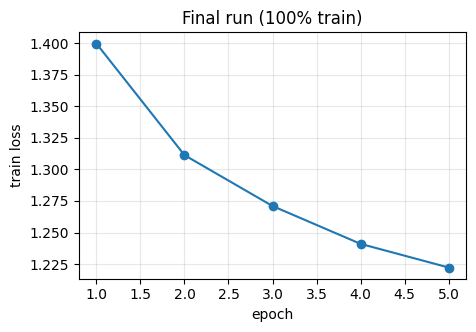

LoRA checkpoint: 5.1 MB (Phase-1 checkpoint is ~1.6 GB)
inference: {'test_docs': 100, 'total_min': 2.907, 'sec_per_doc': 1.744, 'peak_mem_gb': 1.353, 'mean_words': 214.87, 'decode': {'num_beams': 1, 'no_repeat_ngram': 4, 'repetition_penalty': 1.2, 'min_new_tokens': 16, 'max_new_tokens': 512}, 'merged_lora': True}


In [18]:
import matplotlib.pyplot as plt
f = STATE.get("final")
if f:
    h = pd.DataFrame(f["history"]); display(h.round(4))
    print(f"LoRA: r={f['lora']['rank']} alpha={f['lora']['alpha']} targets={f['lora']['targets']} | trainable {f['trainable_params']/1e6:.2f}M of {f['total_params']/1e6:.2f}M ({f['trainable_params']/f['total_params']*100:.2f}%)")
    plt.figure(figsize=(5, 3.2)); plt.plot(h["epoch"], h["train_loss"], marker="o"); plt.xlabel("epoch"); plt.ylabel("train loss"); plt.grid(alpha=.3); plt.title("Final run (100% train)"); plt.show()
    ck = OUT_DIR/"lora_final.pt"
    if ck.exists(): print(f"LoRA checkpoint: {ck.stat().st_size/1024**2:.1f} MB (Phase-1 checkpoint is ~1.6 GB)")
if "inference" in STATE: print("inference:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in STATE["inference"].items()})